In [59]:
import pandas as pd
import scipy.stats as stats
# import scipy.stats as pearsonr
import matplotlib.pyplot as plt 
import numpy as np
from IPython.display import display
from datetime import datetime

# Data Cleaning

In [28]:
# Read file
df=pd.read_csv("Transjakarta.csv")

# Remove duplicates
df.drop_duplicates()

# Remove transID, payCardBank, payCardName, payCardSex, payCardID columns
df=df.drop(columns= ["payCardBank", "payCardName", "payCardSex", "payCardID"], axis=1)

# Remove rows with null values
df=df.dropna()

In [29]:
# Separate date from tapInTime column
df[["tap_in_date", "tap_in_time"]]=df["tapInTime"].str.split(" ", expand=True)

# Separate date from tapOutTime column
df[["tap_out_date", "tap_out_time"]]=df["tapOutTime"].str.split(" ", expand=True)

In [30]:
df

,transID,payCardBirthDate,corridorID,corridorName,direction,tapInStops,tapInStopsName,tapInStopsLat,tapInStopsLon,stopStartSeq,...,tapOutStopsName,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,tap_in_date,tap_in_time,tap_out_date,tap_out_time
0,EIIW227B8L34VB,2008,5,Matraman Baru - Ancol,1.0,P00142,Pal Putih,-6.184631,106.84402,7,...,Tegalan,-6.203101,106.85715,12.0,2023-04-03 06:00:53,3500.0,2023-04-03,05:21:44,2023-04-03,06:00:53
1,LGXO740D2N47GZ,1997,6C,Stasiun Tebet - Karet via Patra Kuningan,0.0,B01963P,Kemenkes 2,-6.228700,106.83302,13,...,Sampoerna Strategic,-6.217152,106.81892,21.0,2023-04-03 06:40:01,3500.0,2023-04-03,05:42:44,2023-04-03,06:40:01
2,DJWR385V2U57TO,1992,R1A,Pantai Maju - Kota,0.0,B00499P,Gg. Kunir II,-6.133132,106.81435,38,...,Simpang Kunir Kemukus,-6.133731,106.81475,39.0,2023-04-03 06:50:55,3500.0,2023-04-03,05:59:06,2023-04-03,06:50:55
3,JTUZ800U7C86EH,1978,11D,Pulo Gebang - Pulo Gadung 2 via PIK,0.0,B05587P,Taman Elok 1,-6.195743,106.93526,23,...,Raya Penggilingan,-6.183068,106.93194,29.0,2023-04-03 06:28:16,3500.0,2023-04-03,05:44:51,2023-04-03,06:28:16
4,VMLO535V7F95NJ,1982,12,Tanjung Priok - Pluit,0.0,P00239,Sunter Boulevard Barat,-6.149650,106.88900,5,...,Kali Besar Barat,-6.135355,106.81143,15.0,2023-04-03 06:57:03,3500.0,2023-04-03,06:17:35,2023-04-03,06:57:03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37895,ZWEC949B8Q87QG,2004,6B,Ragunan - MH Thamrin via Semanggi,1.0,P00261,Tosari,-6.196892,106.82309,2,...,SMK 57,-6.290967,106.82365,13.0,2023-04-21 19:55:49,3500.0,2023-04-21,18:18:37,2023-04-21,19:55:49
37896,YHHK837P6Y95GN,1974,9N,Pinang Ranti - Pramuka,1.0,P00064,Garuda Taman Mini,-6.290154,106.88116,1,...,Pinang Ranti,-6.291075,106.88634,2.0,2023-04-18 22:28:22,3500.0,2023-04-18,21:52:31,2023-04-18,22:28:22
37897,YXPP627N4G95HO,1976,1T,Cibubur - Balai Kota,1.0,B02873P,Plaza Sentral,-6.216247,106.81676,12,...,Buperta Cibubur,-6.370321,106.89628,14.0,2023-04-04 13:27:25,20000.0,2023-04-04,10:29:47,2023-04-04,13:27:25
37898,RGVK175U2U98UV,1976,JAK.13,Tanah Abang - Jembatan Lima,1.0,B02505P,Museum Textile,-6.188656,106.80954,33,...,JPO Blok G,-6.188861,106.81135,34.0,2023-04-15 20:27:50,0.0,2023-04-15,19:59:26,2023-04-15,20:27:50


# Passengers demographic

In [31]:
# Convert birth year to age, add to new column 
df["Age"]=2023-df["payCardBirthDate"]

# Overview 
age=df["Age"]
age.describe()

count    31730.000000
mean        32.789663
std         13.049288
min         11.000000
25%         22.000000
50%         32.000000
75%         41.000000
max         77.000000
Name: Age, dtype: float64

In [32]:
# Youngest age
min_age= df["Age"].min()
print("Youngest age:", min_age)

# Middle age
median_age= df["Age"].median()
print("Median age:", median_age)

# Oldest age
oldest= 77
print("Oldest age:", oldest)

# Age mean
mean_age=df["Age"].mean()
mean_age=round(mean_age)
print("Average age:", mean_age)

# Calculate mode of ages
mode_age=df["Age"].mode()
print("Age Mode:", mode_age)

Youngest age: 11
Median age: 32.0
Oldest age: 77
Average age: 33
Age Mode: 0    31
Name: Age, dtype: int64


In [33]:
# Count rows to see total number of passengers (+1)
total_passengers=len(df.axes[0])
total_passengers= total_passengers
print("Total number of passengers:", total_passengers)

# Average number of passengers daily
avg_daily_passengers= total_passengers/30  # 30 days in April 
avg_daily_passengers= round(avg_daily_passengers)
print("Average number of passengers daily:", avg_daily_passengers)

Total number of passengers: 31730
Average number of passengers daily: 1058


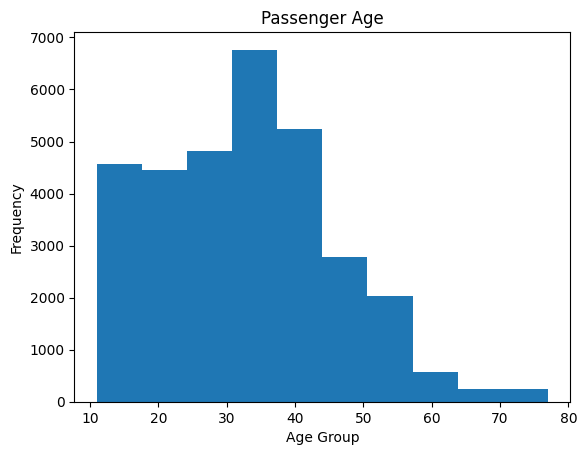

In [34]:
# Histogram
plt.hist(df["Age"])
plt.title("Passenger Age")
plt.xlabel("Age Group")
plt.ylabel("Frequency")
plt.show()


# Calculating travel duration

In [35]:
# Convert timestamp to date time format
df[["tapInTime", "tapOutTime"]] = df[["tapInTime", "tapOutTime"]].apply(pd.to_datetime)

# Calculate travel duration in mins (difference between tap out time and tap in time)
df["travel_duration_mins"] = (df.tapOutTime - df.tapInTime) / pd.Timedelta(minutes=1)

In [36]:
df["travel_duration_mins"]=df["travel_duration_mins"]
df["travel_duration_mins"]=df["travel_duration_mins"].round(2)
display(df["travel_duration_mins"])

0         39.15
1         57.28
2         51.82
3         43.42
4         39.47
          ...  
37895     97.20
37896     35.85
37897    177.63
37898     28.40
37899     26.68
Name: travel_duration_mins, Length: 31730, dtype: float64

In [37]:
# Convert travel duration column from seconds to minutes

# Min value + convert to minutes and rounded
shortest_time=df["travel_duration_mins"].min()
shortest_time=round(shortest_time)
print("Shortest travel duration:", shortest_time, "minutes")

# Average travel duration + convert to minutes and rounded
avg_time=df["travel_duration_mins"].mean()
avg_time=round(avg_time)
print("Average travel duration:", avg_time, "minutes")

# Max value + convert to minutes and rounded
longest_time=df["travel_duration_mins"].max()
max_value=round(longest_time)
print("Longest travel duration:", max_value, "minutes")

Shortest travel duration: 15 minutes
Average travel duration: 72 minutes
Longest travel duration: 179 minutes


# 

In [38]:
# Calculating travel length by number of stops (stopEndSeq-stopStartSeq)
df["no_of_stops"]=df["stopEndSeq"]-df["stopStartSeq"]

In [39]:
# Average number of stops
no_of_stops=df["no_of_stops"].mean()
avg_no_of_stops=round(no_of_stops)
print("Average number of stops:", avg_no_of_stops)

# Min number of stops
min_stops=df["no_of_stops"].min()
min_stops=round(min_stops)
print("Lowest number of stops:", min_stops)

# Max number of stops
max_stops=df["no_of_stops"].max()
max_stops=round(max_stops)
print("Highest number of stops:", max_stops)

# Mode number of stops
mode_stops=df["no_of_stops"].mode()
mode_stops=round(mode_stops)
print("Most number of stops:", mode_stops)

Average number of stops: 8
Lowest number of stops: 1
Highest number of stops: 64
Most number of stops: 0    1.0
Name: no_of_stops, dtype: float64


# How much people spend commuting with TJ per day

In [40]:
# Min value
min_cost=df["payAmount"].min()
lmin_cost=round(min_cost)
print("Minimum amount paid:", min_cost)

# Average cost per day
avg_cost=df["payAmount"].mean()
avg_cost=round(avg_cost)
print("Average amount paid:", avg_cost)

# Max value
max_cost=df["payAmount"].max()
max_cost=round(max_cost)
print("Maximum amount paid:", max_cost)

Minimum amount paid: 0.0
Average amount paid: 2722
Maximum amount paid: 20000


# Busiest and least busiest corridors

In [41]:
# Corridor name overview
df["corridorName"].describe()

count                    31730
unique                     211
top       Cibubur - Balai Kota
freq                       362
Name: corridorName, dtype: object

In [42]:
# See corridorName value counts and sort descending order
print(df["corridorName"].value_counts().sort_values(ascending=True))

corridorName
Kampung Rambutan - Blok M                          16
Tanah Abang - Kebayoran Lama via Pos Pengumben     21
Term. Pulo Gadung - Lampiri                        28
Senen - Tanah Abang                                36
Gondangdia - Balai Kota                            37
                                                 ... 
Kampung Rambutan - Pondok Gede                    305
Pulo Gadung - Monas                               311
Harmoni - Jakarta International Stadium           313
Ciputat - CSW                                     350
Cibubur - Balai Kota                              362
Name: count, Length: 211, dtype: int64


# Busiest tap in and tap out stops name

In [43]:
# Top 5 tap in stops name
tap_in_stops=df["tapInStopsName"].value_counts().sort_values(ascending=False)
tap_in_stops.head(5)

tapInStopsName
Penjaringan          208
Garuda Taman Mini    180
BKN                  149
BNN LRT              139
Pejaten              133
Name: count, dtype: int64

In [44]:
# Top 5 tap out stops name
tap_in_stops=df["tapOutStopsName"].value_counts().sort_values(ascending=False)
tap_in_stops.head(10)

# type(df["tapInStopsName"])

tapOutStopsName
BKN                       274
Penjaringan               236
Term. Senen               175
Term. Kampung Rambutan    144
Monas                     140
Ragunan                   130
Pinang Ranti              129
Kejaksaan Agung           123
Jembatan Item             117
Cibubur Junction          114
Name: count, dtype: int64

In [45]:
# Top 5 tap out stops name
tap_out_stops=(df["tapOutStopsName"].value_counts().sort_values(ascending=False))
tap_out_stops.head(10)

tapOutStopsName
BKN                       274
Penjaringan               236
Term. Senen               175
Term. Kampung Rambutan    144
Monas                     140
Ragunan                   130
Pinang Ranti              129
Kejaksaan Agung           123
Jembatan Item             117
Cibubur Junction          114
Name: count, dtype: int64

# Q7: Finding out busiest and less busiest tap in and tap out time 

In [46]:
# Earliest tap in time
min_tap_in_time= df["tap_in_time"].min()
print("Earliest tap in time:", min_tap_in_time)
 
# Latest tap in time
max_tap_in_time= df["tap_in_time"].max()
print("Latest tap in time:", max_tap_in_time)

df["tap_in_time"].describe()

Earliest tap in time: 05:00:01
Latest tap in time: 21:59:58


count        31730
unique       22029
top       06:57:17
freq             7
Name: tap_in_time, dtype: object

In [47]:
# Earliest tap out time
min_tap_out_time= df["tap_out_time"].min()
print("Earliest tap out time:", min_tap_out_time)
 
# Latest tap out time 
max_tap_out_time= df["tap_out_time"].max()
print("Latest tap out time:", max_tap_out_time)

df["tap_out_time"].describe()

Earliest tap out time: 00:30:08
Latest tap out time: 23:57:50


count        31730
unique       23115
top       18:44:46
freq             7
Name: tap_out_time, dtype: object

# Correlation between number of stops and travel duration

In [60]:
# Convert dataframe into series
no_of_stops= df["no_of_stops"]
travel_duration= df["travel_duration_mins"]

# Pearson Correlation
correlation_coefficient, p_value = stats.pearsonr(no_of_stops, travel_duration)
print("Correlation coefficient:", correlation_coefficient)
print("p value:", p_value)

Correlation coefficient: 0.0067627177689423956
p value: 0.22835636784500618


In [61]:
# Interpreting p value
if p_value < 0.05:
    print("Correlation is statistically significant")
else:
    print("Correlation is not statistically significant")

# Interpreting correlation coefficient
if correlation_coefficient > 0:
    print("There is a positive correlation between number of stops and travel duration")
elif correlation_coefficient < 0:
    print("There is a negative correlation between number of stops and travel duration")
else:
    print("There is no correlation between number of stops and travel duration")

Correlation is not statistically significant
There is a positive correlation between number of stops and travel duration


<function matplotlib.pyplot.show(close=None, block=None)>

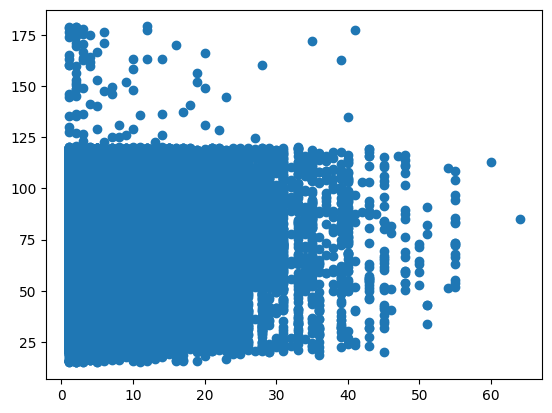

In [ ]:
# Number of stops and travel duration scatter plot

plt.scatter(no_of_stops, travel_duration)
plt.show

In [ ]:
# Modified columns

# "date_only"
dfNew= df[["transID", "Age", "corridorName", "direction", "tap_in_date", "tap_in_time", "tapInStopsName", "tapInStopsLat", "tapInStopsLon", "tap_out_date", "tap_out_time", "tapOutStopsName", "tapOutStopsLat", "tapOutStopsLon", "no_of_stops", "travel_duration_mins", "payAmount"]]
display(dfNew)

# dfNew.to_csv("Transjakarta_data.csv", index=False)


,transID,Age,corridorName,direction,tap_in_date,tap_in_time,tapInStopsName,tapInStopsLat,tapInStopsLon,tap_out_date,tap_out_time,tapOutStopsName,tapOutStopsLat,tapOutStopsLon,no_of_stops,travel_duration_mins,payAmount
0,EIIW227B8L34VB,15,Matraman Baru - Ancol,1.0,2023-04-03,05:21:44,Pal Putih,-6.184631,106.84402,2023-04-03,06:00:53,Tegalan,-6.203101,106.85715,5.0,39.15,3500.0
1,LGXO740D2N47GZ,26,Stasiun Tebet - Karet via Patra Kuningan,0.0,2023-04-03,05:42:44,Kemenkes 2,-6.228700,106.83302,2023-04-03,06:40:01,Sampoerna Strategic,-6.217152,106.81892,8.0,57.28,3500.0
2,DJWR385V2U57TO,31,Pantai Maju - Kota,0.0,2023-04-03,05:59:06,Gg. Kunir II,-6.133132,106.81435,2023-04-03,06:50:55,Simpang Kunir Kemukus,-6.133731,106.81475,1.0,51.82,3500.0
3,JTUZ800U7C86EH,45,Pulo Gebang - Pulo Gadung 2 via PIK,0.0,2023-04-03,05:44:51,Taman Elok 1,-6.195743,106.93526,2023-04-03,06:28:16,Raya Penggilingan,-6.183068,106.93194,6.0,43.42,3500.0
4,VMLO535V7F95NJ,41,Tanjung Priok - Pluit,0.0,2023-04-03,06:17:35,Sunter Boulevard Barat,-6.149650,106.88900,2023-04-03,06:57:03,Kali Besar Barat,-6.135355,106.81143,10.0,39.47,3500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37895,ZWEC949B8Q87QG,19,Ragunan - MH Thamrin via Semanggi,1.0,2023-04-21,18:18:37,Tosari,-6.196892,106.82309,2023-04-21,19:55:49,SMK 57,-6.290967,106.82365,11.0,97.20,3500.0
37896,YHHK837P6Y95GN,49,Pinang Ranti - Pramuka,1.0,2023-04-18,21:52:31,Garuda Taman Mini,-6.290154,106.88116,2023-04-18,22:28:22,Pinang Ranti,-6.291075,106.88634,1.0,35.85,3500.0
37897,YXPP627N4G95HO,47,Cibubur - Balai Kota,1.0,2023-04-04,10:29:47,Plaza Sentral,-6.216247,106.81676,2023-04-04,13:27:25,Buperta Cibubur,-6.370321,106.89628,2.0,177.63,20000.0
37898,RGVK175U2U98UV,47,Tanah Abang - Jembatan Lima,1.0,2023-04-15,19:59:26,Museum Textile,-6.188656,106.80954,2023-04-15,20:27:50,JPO Blok G,-6.188861,106.81135,1.0,28.40,0.0
